multihead
- https://arxiv.org/pdf/1706.03762

In [43]:
from gpt_data import *

In [44]:
class AttentionHead(nn.Module):
	def __init__(self, C, d):
		super().__init__()
		self.B, self.T, self.C, self.d = batchsize, context_size, C, d

		self.Q, self.K, self.V = nn.Linear(self.C, self.d), nn.Linear(self.C, self.d), nn.Linear(self.C, self.d)
		self.mask = torch.tril(torch.ones(self.T, self.T, dtype=torch.bool))

	def forward(self, x):
		# (BTC) @ (Cd) -> (BTd)
		q, k, v = self.Q(x), self.K(x), self.V(x)
		# (BTd) @ (BdT)  -> BTT
		scores = q @ k.mT / self.d**0.5
		scores = scores.masked_fill(~self.mask, float('-inf'))
		att = torch.softmax(scores, dim=-1)
		# (BTT) @ (BTd) -> (BTd)
		return att @ v



class MultiHeadAttention(nn.Module):
	def __init__(self, embedding_size=64, nheads=4):
		super().__init__()

		self.B, self.T, self.C = batchsize, context_size, embedding_size
		self.d = self.C // nheads

		self.embeddings = nn.Embedding(27, self.C)
		self.pos = nn.Embedding(self.T, self.C) 

		self.heads = nn.ModuleList([AttentionHead(self.C, self.d) for _ in range(nheads)])

		self.W0 = nn.Linear(self.C, self.C)

		self.mlp = nn.Sequential(
			nn.Linear(self.C, self.C*4),
			nn.ReLU(),
			nn.Linear(self.C*4, self.C),
			nn.Dropout(0.1)
		)
		self.ln1 = nn.LayerNorm(self.C)
		self.ln2 = nn.LayerNorm(self.C)
		self.ln_f = nn.LayerNorm(self.C)
		self.head = nn.Linear(self.C, 27)
	
	def forward(self, tokens):
		tok_emb, pos_emb = self.embeddings(tokens), self.pos(torch.arange(self.T))
		x = tok_emb + pos_emb            # (B, T, C)
		h = self.ln1(x)

		# multihead
		# BTd cat dim =-1 --> BT(d*nheads) = BTC
		all_heads = torch.cat([attn(h) for attn in self.heads], dim=-1)

		# residual
		x = x + self.W0(all_heads)
		x = x + self.mlp(self.ln2(x))

		logits = self.head(self.ln_f(x)) 
		return logits

mymodel = MultiHeadAttention()

In [45]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mymodel.parameters()) 

lossi = []

for i in range(10000):
	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]

	logits = mymodel(ctx)

	loss = criterion(logits.mT, target)

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

	lossi.append(loss.item())

print(loss.item())

1.1663751602172852


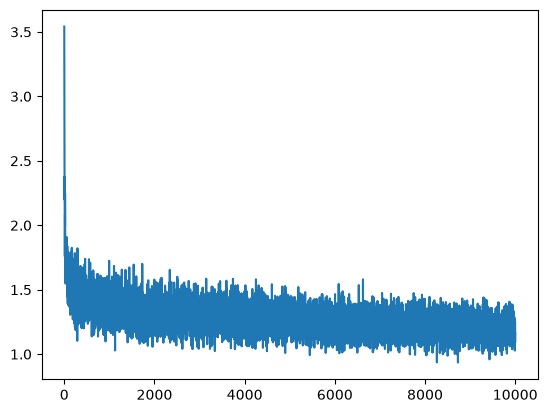

In [47]:
plt.plot(lossi)

In [48]:
alpha = "abcdefghijklmnopqrstuvwxyz."

mymodel.eval() 

for i in range(20):
	ctx = torch.tensor([26] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits[:, -1, :], axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

elea.
llarke.
kryline.
delyn.
lon.
aria.
emaliyah.
alexa.
auriel.
amaday.
kenzla.
meliza.
roselyn.
hada.
kabbrisha.
deline.
junifie.
ha.
makatil.
kelliyah.


In [49]:
@torch.no_grad()
def get_loss(split):
	X, Y = {
		"train": (Xtrain, Ytrain),
		"val": (Xval, Yval)
	}[split]

	ixs = torch.randint(0, X.shape[0], (batchsize,))
	ctx, target = X[ixs], Y[ixs]

	logits = mymodel(ctx)
	loss = F.cross_entropy(logits.view(-1, 27), target.view(-1))

	print(split, loss.item())

get_loss("train")
get_loss("val")

train 1.3410887718200684
val 1.4325778484344482


maybe some overfitting it seems